# 28. Dönem TBMM Tutanakları — Speech Level Table Creation

## Imports & Libraries



In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.max_colwidth", 40)
pd.set_option("display.max_columns", 100)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Uploading CSV

In [ ]:

CSV_PATH = "/content/drive/MyDrive/tbmm_raw_tutanaklar/raw_tutanaklar_28_clean.csv"

# Büyük dosyalarda low_memory=False dtype tahmin sorunlarını azaltır.
df = pd.read_csv(CSV_PATH, low_memory=False)

print("DataFrame shape:", df.shape)
df.head()

DataFrame shape: (342, 13)


,session_id,donem,yasama_yili,birlesim_no,date,list_page_url,ham_page_url,ozet_page_url,ham_html_url,raw_text,raw_text_length,scrape_status,error_message
0,28_4_96,28,4,96,2026-05-20,https://www.tbmm.gov.tr/Tutanaklar/D...,https://www.tbmm.gov.tr/Tutanaklar/T...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,20 Mayıs 2026 Çarşamba\n\nBİRİNCİ OT...,471813,ok,NaN
1,28_4_95,28,4,95,2026-05-14,https://www.tbmm.gov.tr/Tutanaklar/D...,https://www.tbmm.gov.tr/Tutanaklar/T...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...,414584,ok,NaN
2,28_4_94,28,4,94,2026-05-13,https://www.tbmm.gov.tr/Tutanaklar/D...,https://www.tbmm.gov.tr/Tutanaklar/T...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,13 Mayıs 2026 Çarşamba\n\nBİRİNCİ OT...,130983,ok,NaN
3,28_3_114,28,3,114,2025-08-29,https://www.tbmm.gov.tr/Tutanaklar/D...,https://www.tbmm.gov.tr/Tutanaklar/T...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...,267776,ok,NaN
4,28_3_113,28,3,113,2025-07-20,https://www.tbmm.gov.tr/Tutanaklar/D...,https://www.tbmm.gov.tr/Tutanaklar/T...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,https://cdn.tbmm.gov.tr/TbmmWeb/Tuta...,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...,580580,ok,NaN


### Verifications

In [ ]:
print("Kolonlar:")
print(df.columns.tolist())

print(df.info())

Kolonlar:
['session_id', 'donem', 'yasama_yili', 'birlesim_no', 'date', 'list_page_url', 'ham_page_url', 'ozet_page_url', 'ham_html_url', 'raw_text', 'raw_text_length', 'scrape_status', 'error_message']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   session_id       342 non-null    object 
 1   donem            342 non-null    int64  
 2   yasama_yili      342 non-null    int64  
 3   birlesim_no      342 non-null    int64  
 4   date             342 non-null    object 
 5   list_page_url    342 non-null    object 
 6   ham_page_url     342 non-null    object 
 7   ozet_page_url    342 non-null    object 
 8   ham_html_url     342 non-null    object 
 9   raw_text         342 non-null    object 
 10  raw_text_length  342 non-null    int64  
 11  scrape_status    342 non-null    object 
 12  error_message    0 non-null      float64
dt

In [ ]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].isna().sum()

np.int64(0)

In [ ]:
# Eksik değer kontrolü
missing_summary = df.isna().sum().sort_values(ascending=False)
missing_summary[missing_summary > 0]

,0
error_message,342


In [ ]:
# Tamamen tekrar eden satır var mı?
print("Duplicate row count:", df.duplicated().sum())

# Eğer session_id varsa, aynı session_id birden fazla gelmiş mi kontrol et
if "session_id" in df.columns:
    print("Duplicate session_id count:", df["session_id"].duplicated().sum())

Duplicate row count: 0
Duplicate session_id count: 0


In [ ]:
if set(["donem", "yasama_yili", "birlesim_no"]).issubset(df.columns):
    session_counts = (
        df.groupby(["donem", "yasama_yili"])["birlesim_no"]
        .nunique()
        .reset_index(name="unique_birlesim_count")
        .sort_values(["donem", "yasama_yili"])
    )
    display(session_counts)
else:
    print("donem, yasama_yili veya birlesim_no kolonlarından biri eksik.")

,donem,yasama_yili,unique_birlesim_count
0,28,1,18
1,28,2,114
2,28,3,114
3,28,4,96


In [ ]:
df = df.sort_values(
    ["donem", "yasama_yili", "birlesim_no"]
).reset_index(drop=True)

In [ ]:
important_cols = ["session_id", "donem", "yasama_yili", "birlesim_no", "date"]
display(df[important_cols].drop_duplicates().head(20))


,session_id,donem,yasama_yili,birlesim_no,date
0,28_1_1,28,1,1,2023-06-02
1,28_1_2,28,1,2,2023-06-03
2,28_1_3,28,1,3,2023-06-07
3,28_1_4,28,1,4,2023-06-13
4,28_1_5,28,1,5,2023-06-14
5,28_1_6,28,1,6,2023-06-15
6,28_1_7,28,1,7,2023-06-20
7,28_1_8,28,1,8,2023-06-21
8,28_1_9,28,1,9,2023-06-22
9,28_1_10,28,1,10,2023-07-04


In [ ]:
TEXT_COL = "raw_text"
df["text_len"] = df[TEXT_COL].astype(str).str.len()
df["word_count"] = df[TEXT_COL].astype(str).str.split().str.len()

df[["text_len", "word_count"]].describe()

,text_len,word_count
count,342.000000,342.000000
mean,344342.383041,44318.847953
std,173632.719178,22451.869724
min,492.000000,62.000000
25%,241994.250000,31168.500000
50%,364276.000000,46584.000000
75%,451037.000000,58219.250000
max,864414.000000,110194.000000


In [ ]:
show_cols = [col for col in ["session_id", "donem", "yasama_yili", "birlesim_no", "date", "text_len", "word_count", TEXT_COL] if col in df.columns]

display(df.sort_values("word_count").head(10)[show_cols])

,session_id,donem,yasama_yili,birlesim_no,date,text_len,word_count,raw_text
328,28_4_83,28,4,83,2026-04-16,492,62,16 Nisan 2026 Perşembe\n\nBİRİNCİ OT...
177,28_3_46,28,3,46,2025-01-09,922,122,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
239,28_3_108,28,3,108,2025-07-10,1109,140,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
230,28_3_99,28,3,99,2025-06-19,1109,143,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
185,28_3_54,28,3,54,2025-02-06,1117,148,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
174,28_3_43,28,3,43,2024-12-26,1142,151,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
184,28_3_53,28,3,53,2025-02-05,1179,153,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
159,28_3_28,28,3,28,2024-12-05,1181,157,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
86,28_2_69,28,2,69,2024-04-03,1317,170,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...
299,28_4_54,28,4,54,2026-01-29,1359,178,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTA...


In [ ]:
show_cols_no_text = [col for col in ["session_id", "donem", "yasama_yili", "birlesim_no", "date", "text_len", "word_count"] if col in df.columns]

display(df.sort_values("word_count", ascending=False).head(10)[show_cols_no_text])

,session_id,donem,yasama_yili,birlesim_no,date,text_len,word_count
166,28_3_35,28,3,35,2024-12-15,864414,110194
59,28_2_42,28,2,42,2023-12-21,791582,100921
55,28_2_38,28,2,38,2023-12-17,770008,98644
169,28_3_38,28,3,38,2024-12-18,751654,97374
168,28_3_37,28,3,37,2024-12-17,746134,96055
170,28_3_39,28,3,39,2024-12-19,717930,92505
277,28_4_32,28,4,32,2025-12-14,713788,91646
167,28_3_36,28,3,36,2024-12-16,695994,91609
163,28_3_32,28,3,32,2024-12-12,689579,89481
162,28_3_31,28,3,31,2024-12-11,686082,89024


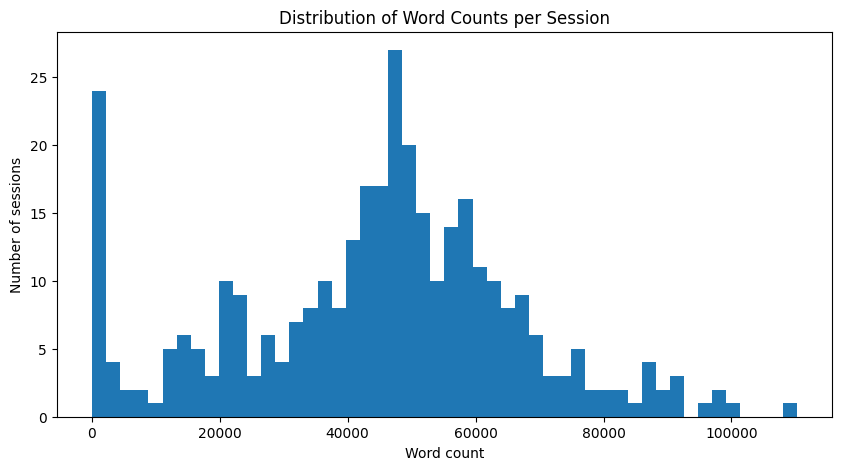

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(df["word_count"].dropna(), bins=50)
plt.xlabel("Word count")
plt.ylabel("Number of sessions")
plt.title("Distribution of Word Counts per Session")
plt.show()

## Basic Text Cleaning

In [ ]:
def basic_clean(text):
    # Temel temizlik: görünmez boşlukları ve fazla whitespace'i düzeltir.
    text = str(text)
    text = text.replace("\xa0", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


df["clean_text"] = df[TEXT_COL].apply(basic_clean)
pd.set_option("display.max_colwidth", 400)
df[[TEXT_COL, "clean_text"]].head(3)

,raw_text,clean_text
0,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTANAK DERGİSİ\n\n1’inci Birleşim\n\n2 Haziran 2023 Cuma\n\n(TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.)\n\nİÇİNDEKİLER\n\nI.- BAŞKANLIĞIN GEN...,TÜRKİYE BÜYÜK MİLLET MECLİSİ TUTANAK DERGİSİ 1’inci Birleşim 2 Haziran 2023 Cuma (TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.) İÇİNDEKİLER I.- BAŞKANLIĞIN GENEL KURULA SUNUŞLAR...
1,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTANAK DERGİSİ\n\n2’nci Birleşim\n\n3 Haziran 2023 Cumartesi\n\n(TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.)\n\nİÇİNDEKİLER\n\nI.- GEÇEN TUTAN...,TÜRKİYE BÜYÜK MİLLET MECLİSİ TUTANAK DERGİSİ 2’nci Birleşim 3 Haziran 2023 Cumartesi (TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.) İÇİNDEKİLER I.- GEÇEN TUTANAK ÖZETİ II.- MAZB...
2,TÜRKİYE BÜYÜK MİLLET MECLİSİ\n\nTUTANAK DERGİSİ\n\n3’üncü Birleşim\n\n7 Haziran 2023 Çarşamba\n\n(TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.)\n\nİÇİNDEKİLER\n\nI.- GEÇEN TUTAN...,TÜRKİYE BÜYÜK MİLLET MECLİSİ TUTANAK DERGİSİ 3’üncü Birleşim 7 Haziran 2023 Çarşamba (TBMM Tutanak Hizmetleri Başkanlığı tarafından hazırlanan bu Tutanak Dergisi’nde yer alan ve kâtip üyeler tarafından okunmuş bulunan her tür belge ile konuşmacılar tarafından ifade edilmiş ve tırnak içinde belirtilmiş alıntı sözler aslına uygun olarak yazılmıştır.) İÇİNDEKİLER I.- GEÇEN TUTANAK ÖZETİ II.- ANT ...


## Speech Level Table Creation


Her tutanaktaki raw text parse edilerek **her konuşmacı ve konuşması ayrı bir satıra** çıkarılır.

Eklenen kolonlar:
- `konusmaci_raw`: Konuşmacının ham ismi (şehir milletvekili bilgisi, Devamla vb. dahil)
- `konusma_text`: Konuşma metni (alkışlar, tepkiler, interruption'lar dahil)
- `konusma_sirasi`: Tutanak içindeki konuşma sırası (1'den başlar)

Regex kuralları 2023 (`–` em dash) ve 2026 (`-` hyphen) formatlarını destekler.

In [ ]:
import re
import pandas as pd

def extract_chair_name(line):
    """
    'BAŞKAN: TBMM Başkan Vekili Bekir Bozdağ' gibi satırlardan başkan adını çıkarır.
    Çıktı örneği: 'BAŞKAN BEKİR BOZDAĞ'
    """
    if not isinstance(line, str):
        return None

    match = re.match(r"^\s*BAŞKAN\s*:\s*(.+)$", line.strip())
    if not match:
        return None

    chair_name = match.group(1).strip()

    # Sık görülen unvan parçalarını temizle.
    chair_name = re.sub(
        r"^(TBMM|Türkiye Büyük Millet Meclisi)\s+",
        "",
        chair_name,
        flags=re.IGNORECASE,
    )
    chair_name = re.sub(
        r"^(TBMM Başkanı|Meclis Başkanı|Başkan Vekili|Geçici Başkan|Başkanı)\s+",
        "",
        chair_name,
        flags=re.IGNORECASE,
    )

    chair_name = chair_name.strip(" .:")
    if not chair_name:
        return None

    return "BAŞKAN " + chair_name.upper()


def find_initial_chair_name(lines):
    """
    İçerik başlangıcından önce kalmış BAŞKAN: satırını da yakalamak için
    tüm tutanak satırlarında ilk başkan bilgisini arar.
    """
    for line in lines:
        chair_name = extract_chair_name(line)
        if chair_name:
            return chair_name
    return None


def normalize_chair_speaker(raw_name, current_chair):
    """
    Konuşmacı adı sadece BAŞKAN ise, eldeki başkan adıyla değiştirir.
    BAŞKAN (Devamla) gibi kalıpları da korur.
    """
    if not current_chair:
        return raw_name

    match = re.match(r"^BAŞKAN\s*(\([^)]+\))?$", raw_name.strip())
    if not match:
        return raw_name

    suffix = match.group(1) or ""
    return f"{current_chair} {suffix}".strip()


def parse_tutanak_speakers(raw_text):
    """
    Tutanak raw text'inden konuşmacıları ve konuşmalarını çıkarır.

    'BAŞKAN – ...' satırları, tutanakta geçen 'BAŞKAN: ...' satırından alınan
    başkan adıyla birlikte 'BAŞKAN AD SOYAD' biçimine dönüştürülür.
    """
    if not isinstance(raw_text, str) or len(raw_text.strip()) == 0:
        return []

    results = []
    lines = raw_text.split("\n")
    current_chair = find_initial_chair_name(lines)

    content_start = 0
    for i, line in enumerate(lines):
        stripped = line.strip()
        if re.match(r"^-{3,}\s*0\s*-{3,}$", stripped):
            content_start = i + 1
            break

    if content_start == 0:
        for i, line in enumerate(lines):
            if re.match(
                r".*(BİRİNCİ|İKİNCİ|ÜÇÜNCÜ|DÖRDÜNCÜ|BEŞİNCİ|ALTINCI)\s+OTURUM",
                line.strip(),
            ):
                content_start = i
                break

    working_lines = lines[content_start:]

    speaker_pattern = re.compile(
        r"^"
        r"((?:[A-ZİŞÇÖÜĞ][A-ZİŞÇÖÜĞa-zışçöüğ]*\.?\s+)*"
        r"[A-ZİŞÇÖÜĞ][A-ZİŞÇÖÜĞ\s''.]+?"
        r"(?:\s*\([^)]+\))?)"
        r"\s*"
        r"[–\-]"
        r"\s*"
        r"(.*)",
        re.MULTILINE,
    )

    def is_valid_speaker_name(name_part):
        name_only = re.sub(r"\([^)]*\)", "", name_part).strip()
        if not name_only:
            return False

        words = name_only.split()
        if len(words) == 0:
            return False

        for word in words:
            clean_word = word.strip(".'\"")
            if not clean_word:
                continue
            if not all(c.isupper() or c in " .'\"" for c in clean_word):
                return False

        return True

    section_pattern = re.compile(
        r"^\s*(?:"
        r"[IVXLCDM]+\.-|"
        r"[A-Z]\)|"
        r"\d+\.-|"
        r"TÜRKİYE BÜYÜK MİLLET MECLİSİ|"
        r"TUTANAK DERGİSİ|"
        r"İÇİNDEKİLER|"
        r"GEÇEN TUTANAK ÖZETİ|"
        r"GELEN KÂĞITLAR"
        r")"
    )

    session_info_pattern = re.compile(
        r"^\s*(?:"
        r"(?:BİRİNCİ|İKİNCİ|ÜÇÜNCÜ|DÖRDÜNCÜ|BEŞİNCİ|ALTINCI)\s+OTURUM|"
        r"Açılma Saati:|"
        r"Kapanma Saati:|"
        r"KÂTİP ÜYELER|"
        r"-{3,}\s*0\s*-{3,}"
        r")"
    )

    current_speaker = None
    current_speech_lines = []
    speech_order = 0

    for line in working_lines:
        stripped = line.strip()

        if not stripped:
            continue

        chair_name = extract_chair_name(stripped)
        if chair_name:
            current_chair = chair_name
            continue

        if section_pattern.match(stripped):
            continue

        if session_info_pattern.match(stripped):
            continue

        match = speaker_pattern.match(stripped)
        if match:
            raw_name = match.group(1).strip()
            speech_text = match.group(2).strip()

            if is_valid_speaker_name(raw_name):
                raw_name = normalize_chair_speaker(raw_name, current_chair)

                if current_speaker is not None:
                    full_speech = " ".join(current_speech_lines).strip()
                    if full_speech:
                        results.append({
                            "konusmaci_raw": current_speaker,
                            "konusma_text": full_speech,
                            "konusma_sirasi": speech_order,
                        })

                speech_order += 1
                current_speaker = raw_name
                current_speech_lines = [speech_text] if speech_text else []
                continue

        if current_speaker is not None:
            current_speech_lines.append(stripped)

    if current_speaker is not None:
        full_speech = " ".join(current_speech_lines).strip()
        if full_speech:
            results.append({
                "konusmaci_raw": current_speaker,
                "konusma_text": full_speech,
                "konusma_sirasi": speech_order,
            })

    return results

In [ ]:

from pathlib import Path

def parse_txt_file(path):
    """Yerel bir txt tutanağını okuyup konuşmacı bazlı satırlara ayırır."""
    path = Path(path)
    with path.open('r', encoding='utf-8') as f:
        return parse_tutanak_speakers(f.read())

def find_group_speaker_source_lines(raw_text, limit=None):
    """Kaynak metinde GRUBU ADINA içeren konuşmacı başlangıç satırlarını bulur."""
    if not isinstance(raw_text, str):
        return []

    matches = []
    for line in raw_text.split('\n'):
        stripped = line.strip()
        if 'GRUBU ADINA' in stripped and ('–' in stripped or '-' in stripped):
            matches.append(stripped)
            if limit is not None and len(matches) >= limit:
                break

    return matches

def summarize_special_speakers(parsed_rows):
    """Parse sonucunda grup adına ve Devamla konuşmacılarını özetler."""
    group_rows = [row for row in parsed_rows if 'GRUBU ADINA' in row['konusmaci_raw']]
    devamla_rows = [row for row in parsed_rows if 'Devamla' in row['konusmaci_raw']]
    return {
        'group_speaker_count': len(group_rows),
        'devamla_speaker_count': len(devamla_rows),
        'group_speakers': group_rows,
        'devamla_speakers': devamla_rows,
    }

def preview_txt_parsing(paths=('tbmm.txt', 'tbmm2.txt'), n=10):
    """Yerel örnek txt dosyaları varsa parse sonucunu kısa biçimde gösterir."""
    available_paths = [Path(path) for path in paths if Path(path).exists()]
    if not available_paths:
        print("Yerel tbmm.txt / tbmm2.txt bulunamadı; df['raw_text'] üzerinden devam edebilirsiniz.")
        return {}

    previews = {}
    for path in available_paths:
        rows = parse_txt_file(path)
        previews[path.name] = rows
        print(f'=== {path.name}: {len(rows)} konuşma ===')
        for row in rows[:n]:
            print(f"  [{row['konusma_sirasi']:3d}] {row['konusmaci_raw']:<55s} | {row['konusma_text'][:70]}...")
        print()

    return previews




In [ ]:
# ============================================================
# Tüm tutanakları parse et ve yeni DataFrame oluştur
# ============================================================

if 'df' not in globals():
    raise NameError("Önce veri yükleme hücrelerini çalıştırıp df DataFrame'ini oluşturun.")
if 'raw_text' not in df.columns:
    raise KeyError("df içinde 'raw_text' kolonu bulunamadı.")

metadata_columns = [
    col for col in [
        'session_id', 'donem', 'yasama_yili', 'birlesim_no', 'date',
        'list_page_url', 'ham_page_url', 'ozet_page_url', 'ham_html_url'
    ]
    if col in df.columns
]
speaker_columns = metadata_columns + ['konusmaci_raw', 'konusma_text', 'konusma_sirasi']
all_speeches = []

for _, row in df.iterrows():
    raw_text = row.get('raw_text', '')
    speeches = parse_tutanak_speakers(raw_text)

    for speech in speeches:
        record = {col: row.get(col, None) for col in metadata_columns}
        record.update(speech)
        all_speeches.append(record)

df_speeches = pd.DataFrame(all_speeches, columns=speaker_columns)
print(f'Toplam {len(df_speeches)} konuşma satırı oluşturuldu ({len(df)} tutanaktan)')
if not df_speeches.empty:
    print(f'Benzersiz konuşmacı sayısı: {df_speeches["konusmaci_raw"].nunique()}')
print()
display(df_speeches.head(20))

Toplam 199158 konuşma satırı oluşturuldu (342 tutanaktan)
Benzersiz konuşmacı sayısı: 2103



,session_id,donem,yasama_yili,birlesim_no,date,list_page_url,ham_page_url,ozet_page_url,ham_html_url,konusmaci_raw,konusma_text,konusma_sirasi
0,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Tam/3fa77d2f-e0ad-452d-81a1-83949e1c8487.html,BAŞKAN DEVLET BAHÇELİ,Türkiye Büyük Millet Meclisinin 28’inci Yasama Döneminin Birinci Yasama Yılının 1’inci Birleşimini açıyorum. Toplantı yeter sayısı vardır.,1
1,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Tam/3fa77d2f-e0ad-452d-81a1-83949e1c8487.html,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, Sayın Cumhurbaşkanı kendilerine ayrılan locadaki yerlerini almak suretiyle Meclisimizi teşrif etmişlerdir. Kendilerine Genel Kurul adına hoş geldiniz diyorum. (AK PARTİ sıralarından ayakta alkışlar, MHP sıralarından alkışlar) Şimdi İstiklal Marşı’mız okunacaktır. (İstiklal Marşı) (Alkışlar)",2
2,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Tam/3fa77d2f-e0ad-452d-81a1-83949e1c8487.html,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, şimdi gündeme geçiyoruz. Gündemimize göre ant içme töreni yapılacaktır fakat ant içme töreninden önce, Geçici Meclis Başkanı sıfatıyla Meclisi, sizleri selamlamak istiyorum.",3
3,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Tam/3fa77d2f-e0ad-452d-81a1-83949e1c8487.html,BAŞKAN DEVLET BAHÇELİ,"Muhterem Cumhurbaşkanım, değerli milletvekilleri; 14 Mayıs 2023 tarihinde yapılan milletvekili genel seçimiyle tecelli eden 28’inci Dönem Türkiye Büyük Millet Meclisinin ilk gündem maddesi olan ant içme törenine geçmeden evvel, Geçici Başkan sıfatıyla hepinizi saygılarımla selamlıyorum. (AK PARTİ ve MHP sıralarından alkışlar) Egemenliğin yegâne sahibi, aynı zamanda mensubiyetinden iftihar etti...",4
4,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Tam/3fa77d2f-e0ad-452d-81a1-83949e1c8487.html,BAŞKAN DEVLET BAHÇELİ,"Esas gündemimiz olan ant içme törenine geçiyor, Geçici Başkan sıfatıyla da ilk yemini gerçekleştiriyorum. “Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet ...",5
5,28_1_1,28,1,1,2023-06-02,https://www.tbmm.gov.tr/Tutanaklar/DoneminTutanakMetinleri?Donem=28&YasamaYili=1,https://www.tbmm.gov.tr/Tutanaklar/Tutanak?Id=1bed32d9-ce17-4913-8564-01887bf9850e,https://cdn.tbmm.gov.tr/TbmmWeb/Tutanak20230120/28/1/1/Ozet/9992694a-ed98-42d2-9f18-e494cfc8e7cd.html,https://cdn.tbm

In [ ]:
# Konuşmacı bazında istatistikler ve özel kalıp kontrolleri
if df_speeches.empty:
    print('df_speeches boş; kontrol üretilecek konuşma yok.')
else:
    print('=== Konuşma sayısına göre en aktif konuşmacılar ===')
    speaker_counts = df_speeches['konusmaci_raw'].value_counts()
    display(speaker_counts.head(20).to_frame('konusma_sayisi'))
    print()

    df_speeches['konusma_uzunlugu'] = df_speeches['konusma_text'].str.len()
    df_speeches['kelime_sayisi'] = df_speeches['konusma_text'].str.split().str.len()
    print('=== Konuşma uzunluğu istatistikleri ===')
    display(df_speeches[['konusma_uzunlugu', 'kelime_sayisi']].describe())
    print()

    group_speakers = df_speeches[df_speeches['konusmaci_raw'].str.contains('GRUBU ADINA', na=False)]
    devamla_speakers = df_speeches[df_speeches['konusmaci_raw'].str.contains('Devamla', na=False)]
    print(f'GRUBU ADINA konuşmacı satırı: {len(group_speakers)}')
    display(group_speakers[['konusma_sirasi', 'konusmaci_raw', 'konusma_text']].head(20))
    print(f'Devamla konuşmacı satırı: {len(devamla_speakers)}')
    display(devamla_speakers[['konusma_sirasi', 'konusmaci_raw', 'konusma_text']].head(20))
    print()

    if 'session_id' in df_speeches.columns:
        sessions_with_speeches = df_speeches['session_id'].nunique()
        print(f'Konuşma bulunan tutanak sayısı: {sessions_with_speeches} / {len(df)}')

if 'df' in globals() and 'raw_text' in df.columns:
    group_source_records = []
    for _, row in df.iterrows():
        for source_line in find_group_speaker_source_lines(row.get('raw_text', '')):
            group_source_records.append({
                'session_id': row.get('session_id', None),
                'date': row.get('date', None),
                'source_line': source_line,
            })
    df_group_source_lines = pd.DataFrame(group_source_records)
    print(f'Kaynak metinde GRUBU ADINA içeren satır sayısı: {len(df_group_source_lines)}')
    display(df_group_source_lines.head(30))

=== Konuşma sayısına göre en aktif konuşmacılar ===


,konusma_sayisi
konusmaci_raw,
BAŞKAN BEKIR BOZDAĞ,19627
BAŞKAN CELAL ADAN,16279
BAŞKAN GÜLIZAR BİÇER KARACA,10892
BAŞKAN SIRRI SÜREYYA ÖNDER,8782
BAŞKAN TEKIN BİNGÖL,7532
BAŞKAN PERVIN BULDAN,5340
ALİ MAHİR BAŞARIR (Mersin),4634
GÖKHAN GÜNAYDIN (İstanbul),3460
GÜLÜSTAN KILIÇ KOÇYİĞİT (Kars),3340



=== Konuşma uzunluğu istatistikleri ===


,konusma_uzunlugu,kelime_sayisi
count,199158.000000,199158.000000
mean,518.052762,66.587348
std,1340.882695,171.959000
min,1.000000,1.000000
25%,31.000000,4.000000
50%,85.000000,11.000000
75%,435.000000,55.000000
max,51917.000000,6668.000000



GRUBU ADINA konuşmacı satırı: 7501


,konusma_sirasi,konusmaci_raw,konusma_text
191,87,AK PARTİ GRUBU ADINA ABDULLAH GÜLER (Sivas),"Saygıdeğer Başkanım, değerli milletvekilleri; yüce Genel Kurulu ve ekranları başındaki aziz milletimi saygıyla selamlıyorum. Grup önerimiz biraz önce detaylı şekilde okundu. Ben birkaç hususa değinerek biraz daha çerçeve içerisinde Genel Kurula bilgi vermek istiyorum. Şimdi, biraz önce değerli milletvekillerimizden, değerli hatiplerimizden birkaçı burada mevcut sayımızın çokluğuyla beraber far..."
217,113,İYİ PARTİ GRUBU ADINA ERHAN USTA (Samsun),"Sayın Başkan, değerli milletvekilleri; AK PARTİ grup önerisi üzerinde, İYİ Parti Grubu adına söz aldım. Hepinizi saygıyla selamlarım. Sayın Başkan, Meclis Başkanlığınız hayırlı olsun. 28’inci Dönemin de milletimize, Meclisimize, ülkemize hayırlı olmasını Cenab-ı Allah'tan niyaz ediyorum. Değerli Başkanım, aslında konu, şu anda tartıştığımız konu, Anayasa’ya uygunluk açısından tartışıldı, Müsav..."
224,120,YEŞİL SOL PARTİ GRUBU ADINA MEHMET RÜŞTÜ TİRYAKİ (Batman),"Teşekkür ediyorum Sayın Başkan. Sayın Başkan ve değerli milletvekilleri; 28’inci Dönemin halklarımıza barış ve hoşgörü getirmesini, bu Meclis grubunun ülkemizin barışına ve hoşgörü içinde yaşayacağımız bir toplum düzenine hizmet edecek çalışmalar yürütmesini diliyorum. Yapar mı, kuşkularım var ama umarım yanılırım. Biz grup olarak toplumsal barışa, hoşgörünün egemen olacağı bir topluma ve uzla..."
228,124,CHP GRUBU ADINA ALİ MAHİR BAŞARIR (Mersin),"Sayın Başkan, değerli milletvekilleri; hepinizi saygıyla selamlıyorum. Aslında Sayın Grup Başkan Vekili Özlem Zengin çok güzel bir şey söyledi “Meseleye hukuken bakabilmek…” Aslında bu, hepimiz için geçerli; bana göre, size göre, ona göre değil, her olayda, her vakada aynı tepkiyi verebilmek. Anayasa 2’inci madde net bir şekilde söylüyor “Türkiye Cumhuriyeti bir hukuk devletidir.” Daha dün bu ..."
680,118,İYİ PARTİ GRUBU ADINA ERHAN USTA (Samsun),"Teşekkür ederim Sayın Başkan. Sayın Başkan, değerli milletvekilleri; hepinizi saygıyla selamlarım. İYİ Parti Grubu olarak, bugün, bu sel felaketlerine ilişkin bir araştırma önergesi getirdik. Küresel koşullar var; işte, yağışlar arttı, iklim değişikliği filan derken artık her sene neredeyse bir sel felaketine maruz kalıyor Türkiye. Bu konunun gerçekten Meclis tarafından araştırılması lazım çün..."
684,122,YEŞİL SOL PARTİ GRUBU ADINA KEZİBAN KONUKCU KOK (İstanbul),"Değerli vekiller, ekranları başında bizleri izleyen sevgili halklarımız; doğa kırımı, iklim krizi kapitalizmin krizinin bir parçasıdır. Kâr odaklı politikalarıyla kapitalist sistem sadece insana değil tüm yaşama, tüm canlılara ve gezegenimize düşman politikalar izlemektedir. İklim krizi bir yandan aşırı yağış ve sele yol açarken bir yandan da kuraklığa yol açmaktadır. İklim krizi orta ve uzun ..."
686,124,CHP GRUBU ADINA MURAT ÇAN (Samsun),"Sayın Başkan, değerli milletvekilleri; Cumhuriyet Halk Partisi Grubu adına söz aldım. Genel Kurulu saygıyla selamlıyorum. Ülkemizi etkisi altına alan ve öneri konusu olan, özellikle son bir aylık zaman diliminde yaşanan yoğun yağışların sebep olduğu sel ve su baskınlarından etkilenen yerlerden biri de benim seçim bölgem Samsun’dur. Son bir aylık süre zarfında farklı tarihlerde Ladik, Canik, Te..."
690,128,AK PARTİ GRUBU ADINA AHMET ÇOLAKOĞLU (Zonguldak),"Sayın Başkan, değerli milletvekilleri; İYİ Parti grup önerisi üzerinde söz almış bulunmaktayım. Genel Kurulu ve aziz milletimizi saygıyla selamlıyorum. 28’inci Yasama Dönemimizde ülkemize hayırlı olsun dileklerinde bulunmak istiyorum. Değerli milletvekilleri, önergede bahsedilen “Hiç önlem alınmıyor.” “Devlet felaketlere karşı hiç tedbir almıyor.” konusu kesinlikle ve kesinlikle yanlıştır. Sel..."
782,220,YEŞİL SOL PARTİ GRUBU ADINA ZÜLKÜF UÇAR (Van),"Sayın Başkan, başlayacağım ama arada, gürültüde önergemiz okundu ama anlaşılmadı."
799,237,İYİ PARTİ GRUBU ADINA ADNAN ŞEFİK ÇİRKİN (Hatay),"Sayın Başkan, değerli milletvekilleri; hepinizi saygıyla selamlarım. Bu araştırma önergeleri üzerinde konuşmal

Devamla konuşmacı satırı: 29046


,konusma_sirasi,konusmaci_raw,konusma_text
12,13,OSMAN GÖKÇEK (Devamla),"Tekrar okuyayım. “Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünde..."
23,24,ŞAHİN TİN (Devamla),"“Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünden ve Anayasaya sa..."
38,39,AYŞE BÖHÜRLER (Devamla),"Peki, tekrar okumam gerekiyorsa."
40,41,AYŞE BÖHÜRLER (Devamla),"Tekrar okuyayım: “Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünde..."
43,44,HASAN BİTMEZ (Devamla),"""Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünden ve Anayasaya sa..."
46,47,CEMİL YAMAN (Devamla),"“Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünden ve Anayasaya sa..."
57,58,MAHMUT TANAL (Devamla),"Peki, teşekkür ederim Değerli Genel Başkanım. “Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyet..."
81,12,MAHMUT ÖZER (Devamla),"“Devletin varlığı ve bağımsızlığını, vatanın ve milletin bölünmez bütünlüğünü, milletin kayıtsız ve şartsız egemenliğini koruyacağıma; hukukun üstünlüğüne, demokratik ve lâik Cumhuriyete ve Atatürk ilke ve inkılaplarına bağlı kalacağıma; toplumun huzur ve refahı, millî dayanışma ve adalet anlayışı içinde herkesin insan haklarından ve temel hürriyetlerden yararlanması ülküsünden ve Anayasaya sa..."
132,28,ABDULLAH GÜLER (Devamla),"Başkanım, üç dakika, beş dakika…."
134,30,ABDULLAH GÜLER (Devamla),Beş dakika olarak Başkanım…



Konuşma bulunan tutanak sayısı: 342 / 342
Kaynak metinde GRUBU ADINA içeren satır sayısı: 7505


,session_id,date,source_line
0,28_1_4,2023-06-13,"AK PARTİ GRUBU ADINA ABDULLAH GÜLER (Sivas) – Saygıdeğer Başkanım, değerli milletvekilleri; yüce Genel Kurulu ve ekranları başındaki aziz milletimi saygıyla selamlıyorum."
1,28_1_4,2023-06-13,"İYİ PARTİ GRUBU ADINA ERHAN USTA (Samsun) – Sayın Başkan, değerli milletvekilleri; AK PARTİ grup önerisi üzerinde, İYİ Parti Grubu adına söz aldım. Hepinizi saygıyla selamlarım."
2,28_1_4,2023-06-13,YEŞİL SOL PARTİ GRUBU ADINA MEHMET RÜŞTÜ TİRYAKİ (Batman) – Teşekkür ediyorum Sayın Başkan.
3,28_1_4,2023-06-13,"CHP GRUBU ADINA ALİ MAHİR BAŞARIR (Mersin) – Sayın Başkan, değerli milletvekilleri; hepinizi saygıyla selamlıyorum."
4,28_1_7,2023-06-20,İYİ PARTİ GRUBU ADINA ERHAN USTA (Samsun) – Teşekkür ederim Sayın Başkan.
5,28_1_7,2023-06-20,"YEŞİL SOL PARTİ GRUBU ADINA KEZİBAN KONUKCU KOK (İstanbul) – Değerli vekiller, ekranları başında bizleri izleyen sevgili halklarımız; doğa kırımı, iklim krizi kapitalizmin krizinin bir parçasıdır. Kâr odaklı politikalarıyla kapitalist sistem sadece insana değil tüm yaşama, tüm canlılara ve gezegenimize düşman politikalar izlemektedir. İklim krizi bir yandan aşırı yağış ve sele yol açarken bir ..."
6,28_1_7,2023-06-20,"CHP GRUBU ADINA MURAT ÇAN (Samsun) – Sayın Başkan, değerli milletvekilleri; Cumhuriyet Halk Partisi Grubu adına söz aldım. Genel Kurulu saygıyla selamlıyorum."
7,28_1_7,2023-06-20,"AK PARTİ GRUBU ADINA AHMET ÇOLAKOĞLU (Zonguldak) - Sayın Başkan, değerli milletvekilleri; İYİ Parti grup önerisi üzerinde söz almış bulunmaktayım. Genel Kurulu ve aziz milletimizi saygıyla selamlıyorum."
8,28_1_7,2023-06-20,"YEŞİL SOL PARTİ GRUBU ADINA ZÜLKÜF UÇAR (Van) – Sayın Başkan, başlayacağım ama arada, gürültüde önergemiz okundu ama anlaşılmadı."
9,28_1_7,2023-06-20,"İYİ PARTİ GRUBU ADINA ADNAN ŞEFİK ÇİRKİN (Hatay) - Sayın Başkan, değerli milletvekilleri; hepinizi saygıyla selamlarım."


In [ ]:
# Örnek bir tutanaktan konuşmalar
sample_session = df_speeches['session_id'].iloc[0] if len(df_speeches) > 0 else None
if sample_session:
    sample = df_speeches[df_speeches['session_id'] == sample_session].head(15)
    pd.set_option('display.max_colwidth', 100)
    display(sample[['konusma_sirasi', 'konusmaci_raw', 'konusma_text']])
    pd.set_option('display.max_colwidth', 40)

,konusma_sirasi,konusmaci_raw,konusma_text
0,1,BAŞKAN DEVLET BAHÇELİ,Türkiye Büyük Millet Meclisinin 28’inci Yasama Döneminin Birinci Yasama Yılının 1’inci Birleşimi...
1,2,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, Sayın Cumhurbaşkanı kendilerine ayrılan locadaki yerlerini almak suretiyl..."
2,3,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, şimdi gündeme geçiyoruz. Gündemimize göre ant içme töreni yapılacaktır fa..."
3,4,BAŞKAN DEVLET BAHÇELİ,"Muhterem Cumhurbaşkanım, değerli milletvekilleri; 14 Mayıs 2023 tarihinde yapılan milletvekili g..."
4,5,BAŞKAN DEVLET BAHÇELİ,"Esas gündemimiz olan ant içme törenine geçiyor, Geçici Başkan sıfatıyla da ilk yemini gerçekleşt..."
5,6,BAŞKAN DEVLET BAHÇELİ,İstanbul Milletvekili Sayın Yücel Arzen Hacıoğulları. (AK PARTİ sıralarından alkışlar) (İstanbul...
6,7,BAŞKAN DEVLET BAHÇELİ,Şimdi ant içmek üzere sırasıyla milletvekillerinin isimlerini okutuyorum: ADANA: Faruk Aytek Ayh...
7,8,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, ant içme sırası Ankara milletvekillerine gelmiştir. Şimdiye kadar olduğu ..."
8,9,BAŞKAN DEVLET BAHÇELİ,"Sağ olun efendim. Sayın milletvekilleri, Sayın Cumhurbaşkanımız Genel Kurul salonundan ayrılmakt..."
9,10,BAŞKAN DEVLET BAHÇELİ,"Sayın milletvekilleri, ant içmeye Ankara ili milletvekillerinden devam ediyoruz. ANKARA: Umut Ak..."


In [ ]:
# Yeni dataset'i kaydet
OUTPUT_SPEAKERS_PATH = "tutanaklar_28_konusmaci_bazli.csv"
df_speeches.to_csv(OUTPUT_SPEAKERS_PATH, index=False, encoding='utf-8-sig')
print(f'Konuşmacı bazlı dataset kaydedildi: {OUTPUT_SPEAKERS_PATH}')
print(f'Toplam satır: {len(df_speeches)}')
print(f'Kolonlar: {df_speeches.columns.tolist()}')

Konuşmacı bazlı dataset kaydedildi: tutanaklar_28_konusmaci_bazli.csv
Toplam satır: 199158
Kolonlar: ['session_id', 'donem', 'yasama_yili', 'birlesim_no', 'date', 'list_page_url', 'ham_page_url', 'ozet_page_url', 'ham_html_url', 'konusmaci_raw', 'konusma_text', 'konusma_sirasi', 'konusma_uzunlugu', 'kelime_sayisi']


In [ ]:
import os


DRIVE_FOLDER = '/content/drive/MyDrive/tbmm_raw_tutanaklar'


os.makedirs(DRIVE_FOLDER, exist_ok=True)


output_filename = 'tutanaklar_28_konusmaci_bazli.csv'
DRIVE_OUTPUT_PATH = os.path.join(DRIVE_FOLDER, output_filename)


df_speeches.to_csv(DRIVE_OUTPUT_PATH, index=False, encoding='utf-8-sig')

print(f'Konuşmacı bazlı dataset Google Drive konumuna kaydedildi: {DRIVE_OUTPUT_PATH}')

Konuşmacı bazlı dataset Google Drive konumuna kaydedildi: /content/drive/MyDrive/tbmm_raw_tutanaklar/tutanaklar_28_konusmaci_bazli.csv


# Initial Analysis

## Simple Word Frequency

In [ ]:
def simple_tokenize(text):
    text = str(text).lower()
    # Türkçe karakterleri koruyarak kelime yakala
    tokens = re.findall(r"[a-zçğıöşüâîûİ]+", text)
    return tokens

all_tokens = []
for text in df["clean_text"].dropna():
    all_tokens.extend(simple_tokenize(text))

word_freq = Counter(all_tokens)
word_freq.most_common(50)

[('ve', 332726),
 ('bir', 306479),
 ('bu', 248181),
 ('i', 168755),
 ('sayın', 124674),
 ('başkan', 119250),
 ('de', 113539),
 ('da', 110837),
 ('milletvekili', 74388),
 ('türkiye', 67656),
 ('için', 67423),
 ('parti', 51781),
 ('ne', 50630),
 ('olarak', 50197),
 ('var', 48799),
 ('ilişkin', 42929),
 ('daha', 42020),
 ('olan', 41773),
 ('sıralarından', 41723),
 ('ki', 41445),
 ('çok', 40954),
 ('değerli', 39541),
 ('alkışlar', 38989),
 ('stanbul', 38752),
 ('ama', 38517),
 ('milletvekilleri', 38084),
 ('büyük', 37169),
 ('değil', 36617),
 ('her', 36302),
 ('o', 35526),
 ('tarafından', 35454),
 ('genel', 34805),
 ('ya', 34676),
 ('kabul', 34306),
 ('nin', 33940),
 ('en', 33300),
 ('devam', 32149),
 ('kadar', 30587),
 ('ın', 30222),
 ('buyurun', 30017),
 ('gibi', 29630),
 ('devamla', 29472),
 ('yok', 29142),
 ('biz', 28771),
 ('bugün', 28111),
 ('açıklaması', 28075),
 ('kanun', 27971),
 ('söz', 27332),
 ('burada', 26376),
 ('şimdi', 25798)]

## N-gram Analysis

In [ ]:
def get_ngrams(tokens, n=2):
    return list(zip(*[tokens[i:] for i in range(n)]))

bigrams = get_ngrams(filtered_tokens, n=2)
trigrams = get_ngrams(filtered_tokens, n=3)

bigram_freq = Counter(bigrams)
trigram_freq = Counter(trigrams)

print("Most common bigrams:")
for gram, count in bigram_freq.most_common(30):
    print(" ".join(gram), count)

print("Most common trigrams:")
for gram, count in trigram_freq.most_common(30):
    print(" ".join(gram), count)

Most common bigrams:
türkiye meclisi 10180
merkezî yönetim 9305
edenler etmeyenler 9122
meclisi başkanlığına 6586
cumhuriyet halk 6415
oylarınıza sunuyorum 6358
sunuyorum edenler 6249
yönetim kesin 5966
sıra sayılı 5636
bazı ifadelerine 5617
ali mahi 5289
mahi başarir 5286
grup vekili 4755
başarir mersin 4663
etmeyenler edilmiştir 4410
yer alan 4287
yönetim bütçesi 4266
bülent kaya 4013
kesin hesabı 3899
türkiye cumhuriyeti 3890
sezai temelli 3845
sayılı teklifi 3830
plan bütçe 3822
meclis araştırması 3795
gökhan günaydin 3734
gülüstan kiliç 3671
kiliç koçyi 3671
kanunu teklifi 3576
gündem dışı 3507
ifade etmek 3478
Most common trigrams:
türkiye meclisi başkanlığına 6585
oylarınıza sunuyorum edenler 6247
sunuyorum edenler etmeyenler 6190
ali mahi başarir 5286
mahi başarir mersin 4661
merkezî yönetim kesin 4451
edenler etmeyenler edilmiştir 4393
merkezî yönetim bütçesi 4247
yönetim kesin hesabı 3862
sıra sayılı teklifi 3810
gülüstan kiliç koçyi 3670
gökhan günaydin stanbul 3473
kiliç ko

## Keyword Frequency Checks

In [ ]:
keywords = [
    "ekonomi", "enflasyon", "asgari ücret", "emekli", "deprem",
    "eğitim", "sağlık", "kadın cinayet", "çocuk", "anayasa",
    "terör", "güvenlik", "filistin", "gazze", "tarım", "işsizlik"
]

keyword_counts = []
for kw in keywords:
    count_sessions = df["clean_text"].str.lower().str.contains(kw, regex=False, na=False).sum()
    total_mentions = df["clean_text"].str.lower().str.count(re.escape(kw)).sum()
    keyword_counts.append({"keyword": kw, "session_count": count_sessions, "total_mentions": total_mentions})

keyword_df = pd.DataFrame(keyword_counts).sort_values("total_mentions", ascending=False)
keyword_df

,keyword,session_count,total_mentions
3,emekli,309,20403
8,çocuk,314,19883
0,ekonomi,316,17735
5,eğitim,320,16665
6,sağlık,318,16103
9,anayasa,320,15697
4,deprem,314,13686
14,tarım,312,12330
10,terör,311,11244
1,enflasyon,302,9084


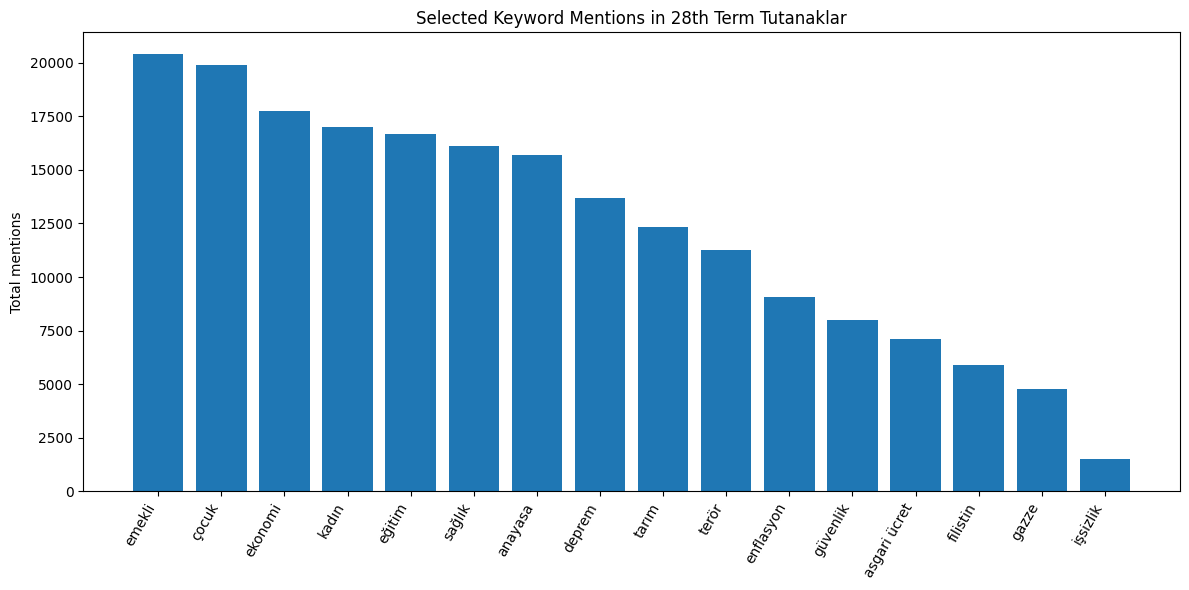

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(keyword_df["keyword"], keyword_df["total_mentions"])
plt.xticks(rotation=60, ha="right")
plt.ylabel("Total mentions")
plt.title("Selected Keyword Mentions in 28th Term Tutanaklar")
plt.tight_layout()
plt.show()